# 04. Gradient Boosting với LightGBM

Notebook tối ưu `LGBMClassifier` bằng CV theo thời gian trên train, sau đó đánh giá một lần trên validation. Test vẫn được giữ kín.

Sản phẩm: `models/gradient_boosting_best_params.json`, hai dòng kết quả trong `reports/results/results.csv`, confusion matrix và permutation importance trên validation trong `reports/figures/`.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
assert (ROOT / "src").is_dir(), f"Không tìm thấy src từ {Path.cwd()}"
PROJECT_ROOT = ROOT
RESULTS_PATH = PROJECT_ROOT / "reports" / "results" / "results.csv"
PARAMS_PATH = PROJECT_ROOT / "models" / "gradient_boosting_best_params.json"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PARAMS_PATH.parent.mkdir(parents=True, exist_ok=True)


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay

from src.config import RANDOM_STATE, TARGET_COLUMN, CLEAN_CATEGORICAL_FEATURES
from src.data import load_raw
from src.evaluate import RESULT_COLUMNS, evaluate_classification, time_series_cv, append_result
from src.features import add_features, ENGINEERED_CATEGORICAL_FEATURES, ENGINEERED_NUMERIC_FEATURES
from src.preprocess import clean_data, build_model_pipeline
from src.split import temporal_split

TARGET = TARGET_COLUMN
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4f}".format)


## 1. Chuẩn bị dữ liệu và feature


In [3]:
raw = load_raw()
clean = clean_data(raw)
df = add_features(clean)

CLEAN_NUMERIC_FEATURES = [
    "lead_time", "arrival_date_week_number", "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
    "adr", "total_of_special_requests",
]
NUMERIC_FEATURES = CLEAN_NUMERIC_FEATURES + list(ENGINEERED_NUMERIC_FEATURES)
CATEGORICAL_FEATURES = list(CLEAN_CATEGORICAL_FEATURES) + list(ENGINEERED_CATEGORICAL_FEATURES)
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
FORBIDDEN = {TARGET, "reservation_status", "reservation_status_date", "arrival_date"}
assert not (set(FEATURES) & FORBIDDEN)
assert set(FEATURES).issubset(df.columns)

train, valid, test = temporal_split(
    df, train_end="2017-01-01", valid_end="2017-07-01", date_col="arrival_date"
)
X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]
print(f"Train: {len(train):,}; validation: {len(valid):,}; test held out: {len(test):,}")
display(pd.DataFrame({"rows": [len(train), len(valid), len(test)], "cancel_rate": [train[TARGET].mean(), valid[TARGET].mean(), test[TARGET].mean()]}, index=["train", "validation", "test"]))


Train: 78,586; validation: 30,386; test held out: 10,233


,rows,cancel_rate
train,78586,0.3622
validation,30386,0.3928
test,10233,0.3712


## 2. Tối ưu siêu tham số bằng time-series CV

Metric chọn mô hình là average precision (PR-AUC). Mỗi pipeline tự fit encoder trên phần train của từng fold.


In [4]:
BASE_PARAMS = {
    "objective": "binary", "random_state": RANDOM_STATE, "n_jobs": -1, "verbosity": -1,
}
PARAM_GRID = [
    {"n_estimators": 300, "learning_rate": 0.05, "num_leaves": 31, "max_depth": -1, "min_child_samples": 30, "subsample": 0.9, "colsample_bytree": 0.9},
    {"n_estimators": 500, "learning_rate": 0.03, "num_leaves": 31, "max_depth": -1, "min_child_samples": 30, "subsample": 0.9, "colsample_bytree": 0.9},
    {"n_estimators": 300, "learning_rate": 0.05, "num_leaves": 63, "max_depth": -1, "min_child_samples": 30, "subsample": 0.9, "colsample_bytree": 0.9},
    {"n_estimators": 300, "learning_rate": 0.05, "num_leaves": 31, "max_depth": 8, "min_child_samples": 50, "subsample": 0.9, "colsample_bytree": 0.9},
]
cv_rows = []
for candidate in PARAM_GRID:
    params = {**BASE_PARAMS, **candidate}
    estimator = LGBMClassifier(**params)
    pipeline = build_model_pipeline(X_train, estimator, numeric_features=NUMERIC_FEATURES, categorical_features=CATEGORICAL_FEATURES, scale_numeric=False)
    scores = time_series_cv(pipeline, X_train, y_train, n_splits=5, scoring="average_precision")
    cv_rows.append({"params": params, "average_precision_mean": float(scores["score"].mean()), "average_precision_std": float(scores["score"].std(ddof=1))})

cv_summary = pd.DataFrame(cv_rows).sort_values("average_precision_mean", ascending=False).reset_index(drop=True)
best_row = cv_summary.iloc[0]
best_params = dict(best_row["params"])
display(cv_summary[["average_precision_mean", "average_precision_std", "params"]])
PARAMS_PATH.write_text(json.dumps(best_params, indent=2, sort_keys=True, default=str) + "\n", encoding="utf-8")
print("Saved best parameters:", PARAMS_PATH.relative_to(PROJECT_ROOT).as_posix())


,average_precision_mean,average_precision_std,params
0,0.7730,0.0105,"{'objective': 'binary', 'random_state': 42, 'n..."
1,0.7691,0.0061,"{'objective': 'binary', 'random_state': 42, 'n..."
2,0.7649,0.0163,"{'objective': 'binary', 'random_state': 42, 'n..."
3,0.7636,0.0087,"{'objective': 'binary', 'random_state': 42, 'n..."


Saved best parameters: models/gradient_boosting_best_params.json


## 3. Fit best model và đánh giá validation


In [5]:
best_pipeline = build_model_pipeline(X_train, LGBMClassifier(**best_params), numeric_features=NUMERIC_FEATURES, categorical_features=CATEGORICAL_FEATURES, scale_numeric=False)
best_pipeline.fit(X_train, y_train)
y_score = best_pipeline.predict_proba(X_valid)[:, 1]
y_pred = (y_score >= 0.5).astype(int)
validation_metrics = evaluate_classification(y_valid, y_pred, y_score)
print(json.dumps(validation_metrics, indent=2))


{
  "average_precision": 0.8054555057427509,
  "f1": 0.6579938377268059,
  "roc_auc": 0.8424565637328625,
  "precision": 0.79038890847139,
  "recall": 0.5635891420911529,
  "TN": 16666.0,
  "FP": 1784.0,
  "FN": 5209.0,
  "TP": 6727.0
}


## 4. Confusion matrix và feature importance

Feature importance được đo bằng **permutation importance trên validation**: xáo trộn giá trị của từng cột gốc rồi đo PR-AUC giảm bao nhiêu (5 lần xáo trộn, `random_state=42`). Cách đo giống notebook 05 (Random Forest) và 06 (Logistic Regression), nên so sánh được giữa ba mô hình.

Không dùng `feature_importances_` của LightGBM (số lần chia nhánh), vì giá trị này được đếm lúc huấn luyện, bị tách theo từng cột one-hot và thiên vị các biến số liên tục, vốn có nhiều ngưỡng để chia.


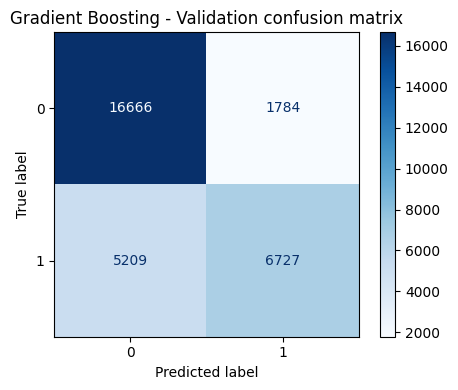

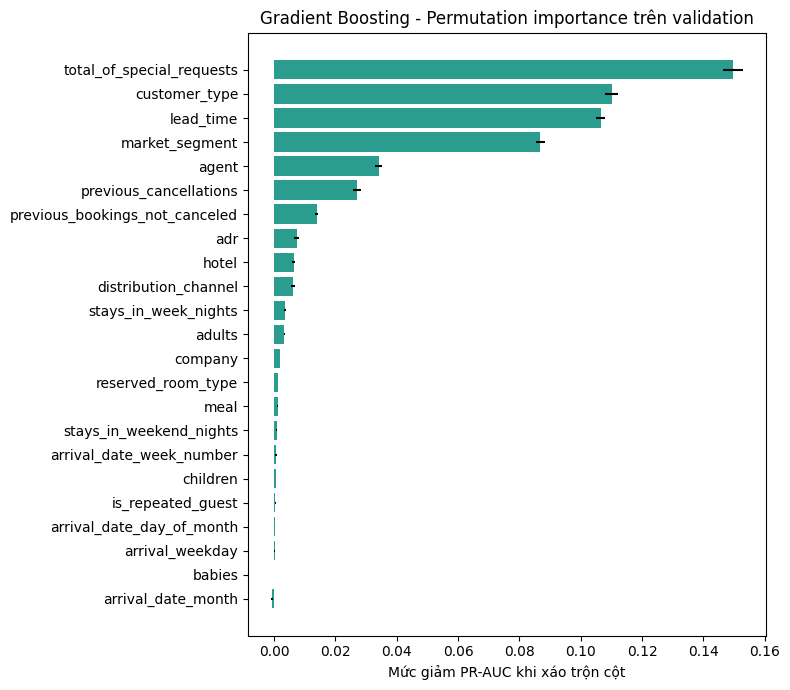

,pr_auc_drop_mean,pr_auc_drop_std
total_of_special_requests,0.1496,0.0031
customer_type,0.1100,0.0023
lead_time,0.1066,0.0015
market_segment,0.0868,0.0015
agent,0.0341,0.0011
previous_cancellations,0.0269,0.0013
previous_bookings_not_canceled,0.0138,0.0005
adr,0.0073,0.0008
hotel,0.0064,0.0004
distribution_channel,0.0062,0.0006


In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_valid, y_pred, cmap="Blues", ax=ax, values_format="d")
ax.set_title("Gradient Boosting - Validation confusion matrix")
fig.tight_layout()
confusion_path = FIGURES_DIR / "gradient_boosting_confusion_matrix.png"
fig.savefig(confusion_path, dpi=160)
plt.show()

# Permutation importance on validation, measured on the 23 original columns
# (same method as notebooks 05 and 06, so the three models can be compared)
perm = permutation_importance(
    best_pipeline, X_valid, y_valid, scoring="average_precision",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=1,
)
importance = pd.DataFrame(
    {"pr_auc_drop_mean": perm.importances_mean, "pr_auc_drop_std": perm.importances_std},
    index=FEATURES,
).sort_values("pr_auc_drop_mean", ascending=False)

order = importance.index[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(order, importance.loc[order, "pr_auc_drop_mean"],
        xerr=importance.loc[order, "pr_auc_drop_std"], color="#2a9d8f")
ax.set_title("Gradient Boosting - Permutation importance trên validation")
ax.set_xlabel("Mức giảm PR-AUC khi xáo trộn cột")
fig.tight_layout()
importance_path = FIGURES_DIR / "gradient_boosting_feature_importance.png"
fig.savefig(importance_path, dpi=160)
plt.show()
display(importance)


## 5. Ghi sản phẩm vào results.csv


In [7]:
# Xóa các dòng do notebook này tạo trước khi ghi lại để Run All là idempotent.
if RESULTS_PATH.exists() and RESULTS_PATH.stat().st_size > 0:
    # Read as text so rows written by other notebooks keep their exact formatting
    existing = pd.read_csv(RESULTS_PATH, dtype=str, keep_default_na=False)
    if list(existing.columns) != RESULT_COLUMNS:
        raise ValueError("results.csv không khớp RESULT_COLUMNS")
    owned = (existing["model_name"].eq("GradientBoosting") & existing["experiment"].eq("main") & existing["feature_set"].eq("clean") & existing["split"].eq("temporal") & existing["eval_set"].isin(["cv", "validation"]))
    existing.loc[~owned].to_csv(RESULTS_PATH, index=False)

append_result({"model_name": "GradientBoosting", "experiment": "main", "feature_set": "clean", "split": "temporal", "train_hotel": "all", "eval_hotel": "all", "eval_set": "cv", "average_precision": float(best_row["average_precision_mean"]), "average_precision_std": float(best_row["average_precision_std"]), "params": json.dumps(best_params, sort_keys=True)}, path=str(RESULTS_PATH))
append_result({"model_name": "GradientBoosting", "experiment": "main", "feature_set": "clean", "split": "temporal", "train_hotel": "all", "eval_hotel": "all", "eval_set": "validation", "n_eval": len(valid), "eval_cancel_rate": float(y_valid.mean()), **validation_metrics, "threshold": 0.5, "params": json.dumps(best_params, sort_keys=True)}, path=str(RESULTS_PATH))
print("Saved:", RESULTS_PATH.relative_to(PROJECT_ROOT).as_posix())
display(pd.read_csv(RESULTS_PATH).tail(2))


Saved: reports/results/results.csv


,model_name,experiment,feature_set,split,train_hotel,eval_hotel,eval_set,n_eval,eval_cancel_rate,average_precision,average_precision_std,f1,roc_auc,precision,recall,threshold,cost_scenario,C_FN,C_FP,TN,FP,FN,TP,expected_cost,cost_per_booking,params
20,GradientBoosting,main,clean,temporal,all,all,cv,NaN,NaN,0.7730,0.0105,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0..."
21,GradientBoosting,main,clean,temporal,all,all,validation,30386.0000,0.3928,0.8055,NaN,0.6580,0.8425,0.7904,0.5636,0.5000,NaN,NaN,NaN,16666.0000,1784.0000,5209.0000,6727.0000,NaN,NaN,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0..."
